# 04 · Optimizador de programación lineal — PowerShift AI
**Entrada:** `datos_horarios.csv`, `pml_perfil.csv` (salidas del notebook 00).
**Salida:** `costos_diarios.csv` (costo diario sin y con orquestador), que alimenta la prueba pareada del notebook 06.

**Qué simula.** Para cada día con carga de EV, el optimizador reparte los kWh de ese día en las horas permitidas minimizando el costo, con el PML como precio y una potencia máxima por hora:

$$\min \sum_t \frac{PML_t}{1000}\,x_t \quad \text{s.a.}\quad \sum_t x_t = E_{EV},\;\; 0 \le x_t \le P_{max}\,a_t$$

La **bomba de calor no se mueve** (restricción de confort: se mantiene tal como se midió). Por eso el costo "controlable" incluye EV + bomba de calor, pero el ahorro viene solo del EV.

**Limitaciones que deben declararse:** (i) el PML es un perfil típico de un solo día aplicado a todos los días; (ii) la carga de EV se supone movible dentro del mismo día en la ventana permitida; (iii) es una simulación, no una medición.

**Parte 2.** Compara la ventana fija de 18:00 a 08:00 h contra ventanas aprendidas del hábito de carga

In [2]:
import numpy as np
import pandas as pd
from scipy.optimize import linprog
import matplotlib.pyplot as plt

UMBRAL_EV_KWH = 0.5     # un día cuenta como "con carga de EV" si carga al menos esto
VENTANAS = {
    "noche": list(range(18, 24)) + list(range(0, 8)),   # 18:00-08:00 (el auto está en casa)
    "24h": list(range(24)),                             # sensibilidad: sin restricción de ventana
}

horario = pd.read_csv("datos_horarios.csv", index_col=0, parse_dates=True)
pml = pd.read_csv("pml_perfil.csv").set_index("hora")["pml_sin"].sort_index().to_numpy()
P_MAX_EV = np.ceil(horario["ev"].max() * 10) / 10      # potencia máxima observada del EV (kW)
print("P_max EV (kW):", P_MAX_EV)

P_max EV (kW): 3.2


In [3]:
def optimizar_ev(energia_kwh, pml, horas_permitidas, p_max):
    """Reparte energia_kwh en las 24 horas minimizando el costo (PL)."""
    c = pml / 1000.0
    cotas = [(0, p_max if h in horas_permitidas else 0.0) for h in range(24)]
    res = linprog(c, A_eq=[np.ones(24)], b_eq=[energia_kwh], bounds=cotas, method="highs")
    return res.x if res.success else None

In [4]:
filas = []
asignacion = {k: np.zeros(24) for k in VENTANAS}
for fecha, g in horario.groupby("fecha"):
    g = g.sort_values("hora")
    ev = g["ev"].to_numpy(); hp = g["heat_pump"].to_numpy()
    E = ev.sum()
    if E < UMBRAL_EV_KWH:
        continue
    fila = {"fecha": fecha, "e_ev_kwh": E,
            "costo_sin": (ev + hp) @ pml / 1000.0,
            "costo_ev_sin": ev @ pml / 1000.0}
    for nombre, horas in VENTANAS.items():
        x = optimizar_ev(E, pml, horas, P_MAX_EV)
        if x is None:
            x = ev                                   # sin solución factible: se deja igual
        assert np.isclose(x.sum(), E)                # se conserva la energía
        fila[f"costo_con_{nombre}"] = (x + hp) @ pml / 1000.0
        fila[f"costo_ev_con_{nombre}"] = x @ pml / 1000.0
        asignacion[nombre] += x
    filas.append(fila)

costos = pd.DataFrame(filas)
costos.to_csv("costos_diarios.csv", index=False)
print("Días con carga de EV:", len(costos), "de", horario['fecha'].nunique(), "días completos")

Días con carga de EV: 268 de 506 días completos


In [5]:
for nombre in VENTANAS:
    sin, con = costos["costo_sin"], costos[f"costo_con_{nombre}"]
    ev_sin, ev_con = costos["costo_ev_sin"], costos[f"costo_ev_con_{nombre}"]
    print(f"--- Ventana {nombre} ---")
    print(f"Costo medio diario sin orquestador (EV + bomba de calor): {sin.mean():.3f} MXN")
    print(f"Costo medio diario con orquestador:                       {con.mean():.3f} MXN")
    print(f"Ahorro medio diario: {(sin-con).mean():.3f} MXN  ({100*(sin-con).sum()/sin.sum():.1f} % del costo controlable,"
          f" {100*(ev_sin-ev_con).sum()/ev_sin.sum():.1f} % del costo del EV)")

horas_top = np.argsort(asignacion["noche"])[::-1][:6]
print("Horas con más energía asignada (ventana noche):", sorted(horas_top.tolist()))

--- Ventana noche ---
Costo medio diario sin orquestador (EV + bomba de calor): 11.059 MXN
Costo medio diario con orquestador:                       8.830 MXN
Ahorro medio diario: 2.228 MXN  (20.2 % del costo controlable, 54.3 % del costo del EV)
--- Ventana 24h ---
Costo medio diario sin orquestador (EV + bomba de calor): 11.059 MXN
Costo medio diario con orquestador:                       8.799 MXN
Ahorro medio diario: 2.260 MXN  (20.4 % del costo controlable, 55.0 % del costo del EV)
Horas con más energía asignada (ventana noche): [2, 3, 4, 5, 7, 23]


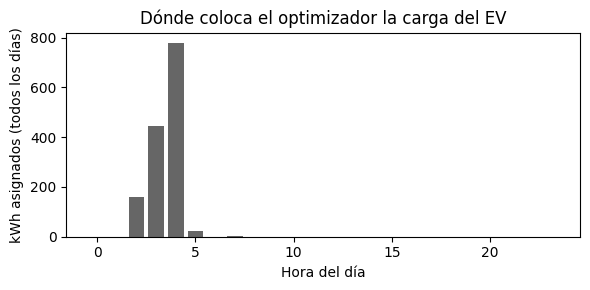

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(24), asignacion["noche"], color="0.4")
ax.set_xlabel("Hora del día"); ax.set_ylabel("kWh asignados (todos los días)")
ax.set_title("Dónde coloca el optimizador la carga del EV")
fig.tight_layout()
fig.savefig("fig_asignacion_ev.pdf"); fig.savefig("fig_asignacion_ev.png", dpi=150)

## Parte 2 · Ventana de carga aprendida del hábito (conexión con el notebook 02)

**Por qué.** En el notebook 02 el EV carga sobre todo entre las 10:00 y las 17:00 h (83 % de su energía) y solo 7.2 % de noche. El supuesto de 18:00 a 08:00 h de la Parte 1 es entonces un **escenario hipotético**. Aquí se definen ventanas con la probabilidad de carga por hora estimada **solo con el año de entrenamiento** (hasta el 13 oct 2016) y se evalúan en los días de **prueba** (14 oct 2016 en adelante), sin ver el futuro.

**Cómo.**
1. P(carga | hora) = media a posteriori Beta-Binomial con el año de entrenamiento (mismo prior débil del notebook 02, fuerza 0.05).
2. Ventana aprendida con umbral τ: las horas con P(carga | hora) ≥ τ. Se prueban τ = 0.02, 0.05 y 0.10 (análisis de sensibilidad).
3. En cada día de prueba con EV (≥ 0.5 kWh), el programa lineal reparte la energía real del día en las horas de la ventana, igual que en la Parte 1, y se compara con el costo observado.
4. Si el día no cabe en la ventana (energía > potencia máxima × horas de la ventana), se deja la carga observada (ahorro 0) y se cuenta como día no factible.

**Limitación que debe declararse.** El LP supone que el auto está conectado y puede cargar a 3.2 kW en cualquier hora de la ventana; OPSD no registra cuándo se conecta el auto. La *cobertura* (qué parte de la energía real cae dentro de la ventana) indica qué tan razonable es ese supuesto.

In [7]:
CORTE = pd.Timestamp("2016-10-13")      # último día de entrenamiento (igual que el notebook 02)
UMBRAL_Y = 0.1                          # kW: el EV "está cargando" (igual que el notebook 02)
FUERZA_PRIOR = 0.05                     # prior Beta débil, igual que el modelo Beta-Binomial del notebook 02

horario["fecha_dt"] = pd.to_datetime(horario["fecha"])
horario["y"] = (horario["ev"] > UMBRAL_Y).astype(int)
entr = horario[horario["fecha_dt"] <= CORTE]
prueba = horario[horario["fecha_dt"] > CORTE]
print("Entrenamiento:", entr["fecha"].min(), "->", entr["fecha"].max(), "|", entr["fecha"].nunique(), "días")
print("Prueba:       ", prueba["fecha"].min(), "->", prueba["fecha"].max(), "|", prueba["fecha"].nunique(), "días")

# P(carga | hora) con el año de entrenamiento (media a posteriori Beta-Binomial)
p0 = entr["y"].mean()
g = entr.groupby("hora")["y"].agg(k="sum", n="count")
theta = ((FUERZA_PRIOR * p0 + g["k"]) / (FUERZA_PRIOR + g["n"])).reindex(range(24))
print(f"Tasa de carga de entrenamiento p0 = {p0:.4f} (puede diferir un poco del 0.0844 del notebook 02, que descarta los primeros días sin historia)")
print("\nP(carga | hora), entrenamiento:")
print(theta.round(3).to_string())

Entrenamiento: 2015-10-14 -> 2016-10-13 | 364 días
Prueba:        2016-10-14 -> 2017-03-05 | 142 días
Tasa de carga de entrenamiento p0 = 0.0849 (puede diferir un poco del 0.0844 del notebook 02, que descarta los primeros días sin historia)

P(carga | hora), entrenamiento:
hora
0     0.003
1     0.006
2     0.003
3     0.000
4     0.000
5     0.000
6     0.000
7     0.006
8     0.033
9     0.074
10    0.137
11    0.201
12    0.264
13    0.310
14    0.272
15    0.209
16    0.192
17    0.148
18    0.099
19    0.049
20    0.014
21    0.008
22    0.008
23    0.003


In [8]:
TAUS = [0.02, 0.05, 0.10]
ventanas2 = {"noche_18_08": VENTANAS["noche"]}
for t in TAUS:
    ventanas2[f"aprendida_p{int(round(100 * t)):02d}"] = [h for h in range(24) if theta[h] >= t]
ventanas2["libre_24h"] = VENTANAS["24h"]

for nombre, horas in ventanas2.items():
    horas = sorted(horas)
    resumen = f"{horas[0]}-{horas[-1]} h" if len(horas) > 0 and horas == list(range(horas[0], horas[-1] + 1)) else str(horas)
    print(f"{nombre:18s} {len(horas):2d} horas  {resumen}")

noche_18_08        14 horas  [0, 1, 2, 3, 4, 5, 6, 7, 18, 19, 20, 21, 22, 23]
aprendida_p02      12 horas  8-19 h
aprendida_p05      10 horas  9-18 h
aprendida_p10       8 horas  10-17 h
libre_24h          24 horas  0-23 h


In [9]:
filas2 = []
asig2 = {k: np.zeros(24) for k in ventanas2}
obs2 = np.zeros(24)
for fecha, gdia in prueba.groupby("fecha"):
    gdia = gdia.sort_values("hora")
    ev = gdia["ev"].to_numpy(); hp = gdia["heat_pump"].to_numpy()
    E = ev.sum()
    if E < UMBRAL_EV_KWH:
        continue
    obs2 += ev
    fila = {"fecha": fecha, "e_ev_kwh": E, "costo_ev_sin": ev @ pml / 1000.0}
    for nombre, horas in ventanas2.items():
        x = optimizar_ev(E, pml, horas, P_MAX_EV)
        factible = x is not None
        if not factible:
            x = ev                                    # no cabe en la ventana: se deja la carga observada
        assert np.isclose(x.sum(), E)
        fila[f"costo_ev_con_{nombre}"] = x @ pml / 1000.0
        fila[f"factible_{nombre}"] = bool(factible)
        fila[f"cobertura_{nombre}"] = ev[list(horas)].sum() / E if len(horas) else 0.0
        asig2[nombre] += x
    filas2.append(fila)

c2 = pd.DataFrame(filas2)
c2.to_csv("costos_ventana_aprendida.csv", index=False)
print("Días de prueba con carga de EV:", len(c2), "de", prueba["fecha"].nunique(), "días de prueba")
print("Costo medio diario del EV observado:", round(c2["costo_ev_sin"].mean(), 3), "MXN")

tabla2 = []
for nombre, horas in ventanas2.items():
    ahorro = c2["costo_ev_sin"] - c2[f"costo_ev_con_{nombre}"]
    tabla2.append(dict(ventana=nombre, horas=len(horas),
                       dias_no_factibles=int((~c2[f"factible_{nombre}"]).sum()),
                       cobertura_pct=100 * c2[f"cobertura_{nombre}"].mean(),
                       ahorro_medio_mxn=ahorro.mean(),
                       ahorro_pct_costo_ev=100 * ahorro.sum() / c2["costo_ev_sin"].sum()))
tabla2 = pd.DataFrame(tabla2).set_index("ventana")
print()
print(tabla2.round(2).to_string())

Días de prueba con carga de EV: 83 de 142 días de prueba
Costo medio diario del EV observado: 4.146 MXN

               horas  dias_no_factibles  cobertura_pct  ahorro_medio_mxn  ahorro_pct_costo_ev
ventana                                                                                      
noche_18_08       14                  0           4.42              2.22                53.50
aprendida_p02     12                  0          98.33              2.25                54.16
aprendida_p05     10                  0          96.75              2.23                53.82
aprendida_p10      8                  0          93.58              2.14                51.50
libre_24h         24                  0         100.00              2.25                54.27


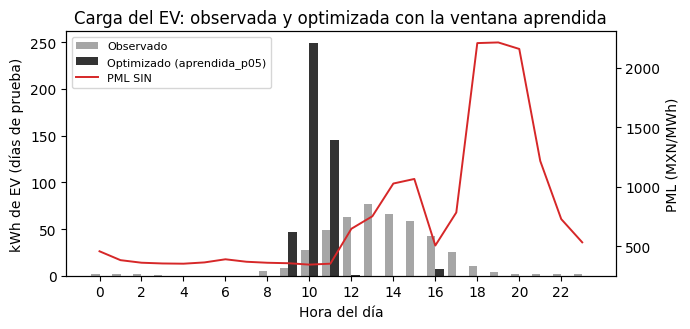

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ancho = 0.4
x = np.arange(24)
ax.bar(x - ancho / 2, obs2, width=ancho, color="0.65", label="Observado")
clave = "aprendida_p05"
ax.bar(x + ancho / 2, asig2[clave], width=ancho, color="0.2", label=f"Optimizado ({clave})")
ax.set_xlabel("Hora del día"); ax.set_ylabel("kWh de EV (días de prueba)")
ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx(); ax2.plot(x, pml, color="tab:red", lw=1.4, label="PML SIN")
ax2.set_ylabel("PML (MXN/MWh)"); ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
ax.set_title("Carga del EV: observada y optimizada con la ventana aprendida")
fig.tight_layout()
fig.savefig("fig_asignacion_ventana.pdf"); fig.savefig("fig_asignacion_ventana.png", dpi=150)

In [11]:
import json
salida = dict(
    entrenamiento=dict(inicio=str(entr["fecha"].min()), fin=str(entr["fecha"].max()), dias=int(entr["fecha"].nunique()), p0=float(p0)),
    prueba=dict(inicio=str(prueba["fecha"].min()), fin=str(prueba["fecha"].max()), dias=int(prueba["fecha"].nunique()), dias_con_ev=int(len(c2))),
    theta_por_hora={int(h): float(v) for h, v in theta.items()},
    ventanas={k: sorted(int(h) for h in v) for k, v in ventanas2.items()},
    costo_ev_observado_medio=float(c2["costo_ev_sin"].mean()),
    tabla={k: {c: float(v) for c, v in fila.items()} for k, fila in tabla2.to_dict("index").items()},
)
json.dump(salida, open("resultados_optimizador.json", "w"), indent=1, ensure_ascii=False)
print("Guardado resultados_optimizador.json, costos_ventana_aprendida.csv y fig_asignacion_ventana.*")

Guardado resultados_optimizador.json, costos_ventana_aprendida.csv y fig_asignacion_ventana.*


## Parte 3 · Exportar la programación para la base de datos (notebook 01)
Guarda en `programacion.csv` la salida **simulada** del optimizador (ventana nocturna de la Parte 1): para cada día con EV, la energía asignada a cada hora y su costo. El notebook 01 la carga en la tabla `programacion` y verifica que la base de datos reproduzca estos costos.

In [12]:
filas_prog = []
for fecha, g in horario.groupby("fecha"):
    g = g.sort_values("hora")
    ev = g["ev"].to_numpy(); E = ev.sum()
    if E < UMBRAL_EV_KWH:
        continue
    x = optimizar_ev(E, pml, VENTANAS["noche"], P_MAX_EV)
    if x is None:
        x = ev
    for h in range(24):
        if x[h] > 1e-6:
            filas_prog.append({"fecha": fecha, "hora": h, "energia_kwh": x[h], "costo_estimado": x[h] * pml[h] / 1000.0})
prog = pd.DataFrame(filas_prog)
prog.to_csv("programacion.csv", index=False)
print("programacion.csv:", prog.shape, "| días:", prog["fecha"].nunique())
# comprobación: la suma diaria debe coincidir con costo_ev_con_noche de costos_diarios.csv
chk = prog.groupby("fecha")["costo_estimado"].sum()
cd = pd.read_csv("costos_diarios.csv").set_index("fecha")["costo_ev_con_noche"]
print("Máx. diferencia contra costos_diarios.csv (MXN):", float((chk - cd.reindex(chk.index)).abs().max()))

programacion.csv: (572, 4) | días: 268
Máx. diferencia contra costos_diarios.csv (MXN): 8.881784197001252e-16
